In [110]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Dublin Fire Brigade (DFB) and Ambulance (DA) annual incident activity logs (2025)

Fields include incident date, district/area information, and response time data. The fields from MOB through to CD are generated automatically by the vehicle system (either via button press or voice message) and reflect the vehicle’s operational status throughout an incident lifecycle:

* **TOC** – Time the call is received in the control centre
* **ORD** – Time when first vehicle is ordered/mobilised to the incident
* **MOB** – Time when first vehicle becomes mobile to the incident
* **IA** – Time when first vehicle arrives at the incident scene
* **LS** – Leaving scene; time when first ambulance departs for hospital
* **AH** – Arrival time at hospital of first appliance or ambulance
* **MAV** – Time when first vehicle is mobile and available again
* **CD** – Time when last vehicle closes down/back at station-Incident Closure

## Incident priority categories:

* **Echo** – Life-threatening cardiac or respiratory arrest
* **Delta** – Life-threatening incident other than cardiac or respiratory arrest
* **Charlie** – Serious, not life-threatening, immediate response required
* **Bravo** – Serious, not life-threatening, urgent response
* **Alpha** – Non-serious or non-life-threatening incident
* **Omega** – Minor illness or injury

In [111]:
df = pd.read_csv('dfb-ambulance-incidents-2025.csv')
df.head()

,ID,Date,Stat IDS with Stn Name DUB_Station Area,criticality,TOC,ORD,MOB,IA,LS,AH,MAV,CD
0,1,01/01/2025,Kilbarrack Fire Station,D,00:01:21,00:06:36,00:09:24,NaN,NaN,00:54:48,01:58:40,01:58:49
1,2,01/01/2025,Finglas Fire Station,B,00:06:07,00:28:06,00:30:02,NaN,NaN,NaN,00:31:21,00:39:41
2,3,01/01/2025,Swords Fire Station,C,00:09:05,00:34:53,00:37:11,00:53:55,01:18:35,01:37:21,01:46:15,01:47:43
3,4,01/01/2025,Tara Street Fire Station,D,00:12:08,00:18:16,00:18:55,00:22:54,00:35:46,00:37:16,NaN,01:21:23
4,5,01/01/2025,Tallaght Fire Station,D,00:15:47,00:20:04,00:22:14,NaN,NaN,NaN,00:45:21,00:45:33


The name on one of the columns seems to be very long, we are going to shorten it.

In [112]:
df.rename(columns={"Stat IDS with Stn Name DUB_Station Area": "Station"}, inplace=True)
df.head()

,ID,Date,Station,criticality,TOC,ORD,MOB,IA,LS,AH,MAV,CD
0,1,01/01/2025,Kilbarrack Fire Station,D,00:01:21,00:06:36,00:09:24,NaN,NaN,00:54:48,01:58:40,01:58:49
1,2,01/01/2025,Finglas Fire Station,B,00:06:07,00:28:06,00:30:02,NaN,NaN,NaN,00:31:21,00:39:41
2,3,01/01/2025,Swords Fire Station,C,00:09:05,00:34:53,00:37:11,00:53:55,01:18:35,01:37:21,01:46:15,01:47:43
3,4,01/01/2025,Tara Street Fire Station,D,00:12:08,00:18:16,00:18:55,00:22:54,00:35:46,00:37:16,NaN,01:21:23
4,5,01/01/2025,Tallaght Fire Station,D,00:15:47,00:20:04,00:22:14,NaN,NaN,NaN,00:45:21,00:45:33


## Preparing and Cleaning the Data

Get info of the data and check for null values

In [113]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 83233 entries, 0 to 83232
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ID           83233 non-null  int64
 1   Date         83233 non-null  str  
 2   Station      83233 non-null  str  
 3   criticality  83233 non-null  str  
 4   TOC          83233 non-null  str  
 5   ORD          83233 non-null  str  
 6   MOB          81891 non-null  str  
 7   IA           72729 non-null  str  
 8   LS           54199 non-null  str  
 9   AH           55530 non-null  str  
 10  MAV          77238 non-null  str  
 11  CD           83233 non-null  str  
dtypes: int64(1), str(11)
memory usage: 14.9 MB


In [114]:
df.isnull().sum()

ID                 0
Date               0
Station            0
criticality        0
TOC                0
ORD                0
MOB             1342
IA             10504
LS             29034
AH             27703
MAV             5995
CD                 0
dtype: int64

### Missing Values

Seven columns have no gaps (ID, Date, Station, Criticality, TOC, ORD and CD). Before we handle any missing values, lets get the count (%) on how many values are missing.

In [115]:
time_cols = ["MOB", "IA", "LS", "AH", "MAV"]
missing = pd.DataFrame({
    "Missing": df[time_cols].isnull().sum(),
    "% missing": (df[time_cols].isnull().mean() * 100).round(1),
}).sort_values("% missing", ascending=False)
missing

,Missing,% missing
LS,29034,34.9
AH,27703,33.3
IA,10504,12.6
MAV,5995,7.2
MOB,1342,1.6


As we can see, there's lots of missing values on the time columns. Therefore, dropping all of the rows with null values will result on a bias. We will keep every row and only filter missing values only if we analyse the respective variable.

### Formatting Date Column

One of the things we can notice is that the **Date** column is set as a string. It's better if we cast it as a date using Pandas.

In [116]:
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")
df.dtypes

ID                      int64
Date           datetime64[us]
Station                   str
criticality               str
TOC                       str
ORD                       str
MOB                       str
IA                        str
LS                        str
AH                        str
MAV                       str
CD                        str
dtype: object

### Encoding ordinal data

Since the **criticality** may be considered as a categorical, ordinal feature, we might as well encode it.

In [117]:
criticality_values = {
  "E": 5,
  "D": 4,
  "C": 3,
  "B": 2,
  "A": 1,
  "O": 0
}
df["criticality_encoded"] = df["criticality"].map(criticality_values)
df.head()

,ID,Date,Station,criticality,TOC,ORD,MOB,IA,LS,AH,MAV,CD,criticality_encoded
0,1,2025-01-01,Kilbarrack Fire Station,D,00:01:21,00:06:36,00:09:24,NaN,NaN,00:54:48,01:58:40,01:58:49,4
1,2,2025-01-01,Finglas Fire Station,B,00:06:07,00:28:06,00:30:02,NaN,NaN,NaN,00:31:21,00:39:41,2
2,3,2025-01-01,Swords Fire Station,C,00:09:05,00:34:53,00:37:11,00:53:55,01:18:35,01:37:21,01:46:15,01:47:43,3
3,4,2025-01-01,Tara Street Fire Station,D,00:12:08,00:18:16,00:18:55,00:22:54,00:35:46,00:37:16,NaN,01:21:23,4
4,5,2025-01-01,Tallaght Fire Station,D,00:15:47,00:20:04,00:22:14,NaN,NaN,NaN,00:45:21,00:45:33,4


In [118]:
df.isnull().sum()

ID                         0
Date                       0
Station                    0
criticality                0
TOC                        0
ORD                        0
MOB                     1342
IA                     10504
LS                     29034
AH                     27703
MAV                     5995
CD                         0
criticality_encoded        0
dtype: int64

## Getting more from the existing data

Since most of the columns provide useful time data, we might as well get some other information into the dataset. We will reuse a function to calcute the minutes between two times.

In [119]:
def minutes_between(start, end):
    if pd.isnull(start) or pd.isnull(end):
        return np.nan

    diff = (pd.to_timedelta(df[end]) - pd.to_timedelta(df[start])).dt.total_seconds() / 60
    crossed_midnight = diff < -60
    diff[crossed_midnight] += 24 * 60
    return diff

### Dispatch Delay

$ORD - TOC$

* **ORD** Time when first vehicle is ordered/mobilised to the incident
* **TOC** Time of call


In [120]:
df["dispatch_delay"] = minutes_between("TOC", "ORD")

### Travel Time

$MOB - IA$

* **MOB** – Time when first vehicle becomes mobile to the incident
* **IA** – Time when first vehicle arrives at the incident scene


In [121]:
df["travel_time"] = minutes_between("MOB", "IA")

### Response Time

$TOC - IA$

* **TOC** – Time the call is received in the control centre
* **IA** – Time when first vehicle arrives at the incident scene

In [122]:
df["response_time"] = minutes_between("TOC", "IA")

### Job Duration

$CD - TOC$

* **CD** – Time when last vehicle closes down/back at station-Incident Closure
* **TOC** – Time the call is received in the control centre

In [123]:
df["job_duration"] = minutes_between("CD", "TOC")

In [124]:
df.head()

,ID,Date,Station,criticality,TOC,ORD,MOB,IA,LS,AH,MAV,CD,criticality_encoded,dispatch_delay,travel_time,response_time,job_duration
0,1,2025-01-01,Kilbarrack Fire Station,D,00:01:21,00:06:36,00:09:24,NaN,NaN,00:54:48,01:58:40,01:58:49,4,5.250000,NaN,NaN,1322.533333
1,2,2025-01-01,Finglas Fire Station,B,00:06:07,00:28:06,00:30:02,NaN,NaN,NaN,00:31:21,00:39:41,2,21.983333,NaN,NaN,-33.566667
2,3,2025-01-01,Swords Fire Station,C,00:09:05,00:34:53,00:37:11,00:53:55,01:18:35,01:37:21,01:46:15,01:47:43,3,25.800000,16.733333,44.833333,1341.366667
3,4,2025-01-01,Tara Street Fire Station,D,00:12:08,00:18:16,00:18:55,00:22:54,00:35:46,00:37:16,NaN,01:21:23,4,6.133333,3.983333,10.766667,1370.750000
4,5,2025-01-01,Tallaght Fire Station,D,00:15:47,00:20:04,00:22:14,NaN,NaN,NaN,00:45:21,00:45:33,4,4.283333,NaN,NaN,-29.766667


## Task 1: Dataset Summary

### Categorical Data

We have two columns with categorical data: Station and Criticality

In [125]:
criticality_frequency = pd.DataFrame({
    "Count": df["criticality_encoded"].value_counts(),
    "Percentage": (df["criticality_encoded"].value_counts(normalize=True) * 100).round(2),
})
station_frequency = pd.DataFrame({
    "Count": df["Station"].value_counts(),
    "Percentage": (df["Station"].value_counts(normalize=True) * 100).round(2),
})

display(criticality_frequency)
display(station_frequency)

,Count,Percentage
criticality_encoded,,
4,40052,48.12
1,13913,16.72
3,13211,15.87
2,12061,14.49
5,2044,2.46
0,1952,2.35


,Count,Percentage
Station,,
Tallaght Fire Station,14040,16.87
Tara Street Fire Station,10963,13.17
Kilbarrack Fire Station,9171,11.02
Dolphins Barn Fire Station,8763,10.53
Phibsborough Fire Station,8710,10.46
Finglas Fire Station,7614,9.15
Rathfarnharm Fire Station,5060,6.08
Blanchardstown Fire Station,4983,5.99
North Strand Fire Station,4272,5.13


In [126]:
station_priority_pct = pd.crosstab(
  df["Station"],
  df["criticality_encoded"],
  normalize="index"
).mul(100).round(2)

display(station_priority_pct)

criticality_encoded,0,1,2,3,4,5
Station,,,,,,
Balbriggan Fire Station,2.24,15.43,16.87,18.23,44.84,2.40
Blanchardstown Fire Station,2.43,18.98,13.04,17.36,45.94,2.25
Dolphins Barn Fire Station,2.42,18.22,13.53,15.61,47.88,2.33
Donnybrook Fire Station,2.65,20.13,15.82,15.34,43.81,2.26
Dun Laoghaire Fire Station,1.47,13.27,22.42,6.78,43.66,12.39
Finglas Fire Station,2.88,18.20,14.45,16.39,45.88,2.21
Kilbarrack Fire Station,2.16,14.32,14.63,17.41,48.97,2.51
North Strand Fire Station,2.53,17.98,14.65,14.84,47.89,2.11
Phibsborough Fire Station,2.37,18.09,14.71,14.45,48.00,2.38


Given the Incident priority categories:

* **Echo (5)** – Life-threatening cardiac or respiratory arrest
* **Delta (4)** – Life-threatening incident other than cardiac or respiratory arrest
* **Charlie (3)** – Serious, not life-threatening, immediate response required
* **Bravo (2)** – Serious, not life-threatening, urgent response
* **Alpha (1)** – Non-serious or non-life-threatening incident
* **Omega (0)** – Minor illness or injury

We can safely assume that most incidents are of priority *Delta*, followed by Alpha, meaning that calls are either a life-threatening emergency or a non-serious incident. Most calls come from Tallaght Station and Tara Street Fire Stations Respectively. Dún Laoghaire has the least incidents, with only 339 incidents recorded.

### Numerical Data

In [ ]:
df["response_time"].describe()

count    72729.000000
mean        51.756357
std         64.106035
min        -46.583333
25%         15.433333
50%         27.266667
75%         60.833333
max       1352.050000
Name: response_time, dtype: float64

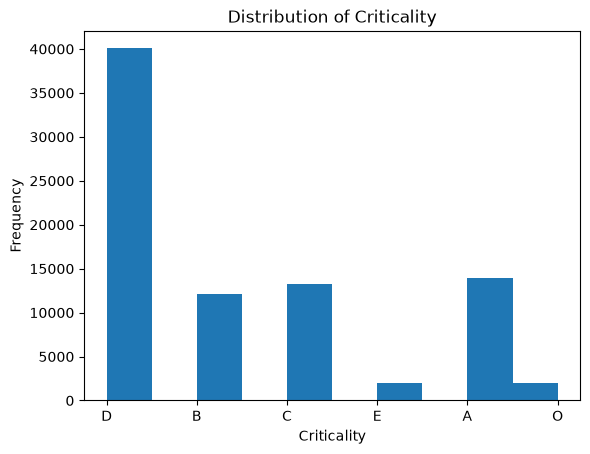

In [128]:
plt.hist(df["criticality"].dropna())
plt.xlabel("Criticality")
plt.ylabel("Frequency")
plt.title("Distribution of Criticality")
plt.show()